# 06 · The German extension

## 1 · Scope

The extension studies drift and reversal in DAX, MDAX and SDAX companies on Xetra.
`DRIFTREV_MARKET=de` selects Germany and a separate data directory.
This notebook reads existing tables and artifacts. It does not fetch data or fit models.


In [1]:
import os
os.environ["DRIFTREV_MARKET"] = "de"
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})
from driftrev import config, store, artifacts, dataset, features, models, simulate, analysis, pipeline
print("data dir:", config.DATA_DIR)
from IPython.display import display
from driftrev import consensus, de_membership
print("market:", config.MARKET)

def table(name):
    df = store.read_table(name)
    if df.empty:
        print(f"missing: {name}")
    return df

def frame(name):
    df = artifacts.load_frame(name)
    if df.empty:
        print(f"missing: {name}")
    return df

data dir: /Users/mac/Documents/New project/stock-data-analysis/project/data/de
market: Market(code='de', name='German equities (Xetra: DAX + MDAX + SDAX)', exchange_mic='XETR', timezone='Europe/Berlin', run_time='18:30', close_time='17:30', currency='EUR', index_set=('dax', 'mdax', 'sdax'), cap_bucket_by_index=(('dax', 'large'), ('mdax', 'mid'), ('sdax', 'small')), benchmarks=(('^GDAXI', 'dax'), ('^MDAXI', 'mdax'), ('^SDAXI', 'sdax')), primary_benchmark='^GDAXI', small_benchmark='^SDAXI', cost_bps_one_way=(('large', 10.0), ('mid', 20.0), ('small', 35.0)), min_dollar_volume=1000000.0, breakout_min_median_turnover=5000000.0, data_subdir='de', implemented=True)


## 2 · Point-in-time universe

Count members at each year end and at the latest stored market date.
If market prices are missing, use today's date for the open membership intervals.
The latest counts are shown beside the expected current index sizes.


index_code,dax,mdax,sdax
date,,,
2014-12-31,30,50,58
2015-12-31,30,50,53
2016-12-31,30,50,50
2017-12-31,30,49,51
2018-12-31,30,59,55
2019-12-31,30,59,56
2020-12-31,30,59,54
2021-12-31,40,49,55
2022-12-31,40,49,57


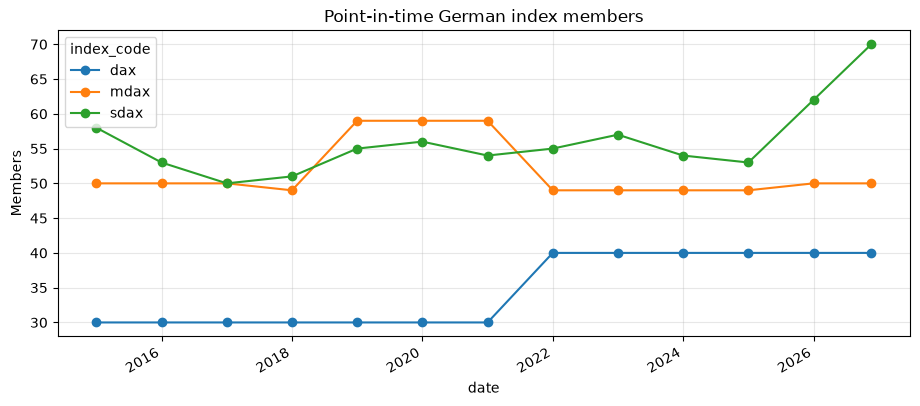

latest date: 2026-11-20


,members,expected_current
dax,40,40
mdax,50,50
sdax,70,70


In [2]:
membership = table("membership_history")
market = table("market")
latest_date = (pd.to_datetime(market["date"]).max().normalize() if not market.empty
               else pd.Timestamp.now(tz="Europe/Berlin").tz_localize(None).normalize())
if not membership.empty:
    for col in ["start_date", "end_date"]:
        membership[col] = pd.to_datetime(membership[col])
    dates = pd.DatetimeIndex([f"{year}-12-31" for year in range(2014, 2026)]).union(
        pd.DatetimeIndex([latest_date]))
    counts = pd.DataFrame({date: de_membership.membership_on(membership, date)
                           .groupby("index_code")["company_key"].nunique()
                           for date in dates}).T.reindex(columns=config.MARKET.index_set).fillna(0).astype(int)
    counts.index.name = "date"
    display(counts)
    counts.plot(marker="o", title="Point-in-time German index members")
    plt.ylabel("Members"); plt.show()
    print("latest date:", latest_date.date())
    display(pd.DataFrame({"members": counts.loc[latest_date],
                          "expected_current": pd.Series({"dax": 40, "mdax": 50, "sdax": 70})}))

SDAX history is partial. MDAX change rows reveal some SDAX moves, but not all exits.
Open SDAX intervals for former members with unknown exit dates are dropped.
This leaves survivorship bias in the early universe. See [OPL R7.2a](../docs/architecture/opm/OPL.md#r7--german-equities-on-deutsche-börse-xetra).


## 3 · Symbols and prices

Show how symbols were resolved and which venues supply prices.
Keep companies without a symbol visible.


In [3]:
universe = table("universe")
prices_de = table("prices")
if not universe.empty:
    display(universe.groupby(["price_source", "resolved_by"], dropna=False).size().rename("companies").to_frame())
    unresolved = universe["symbol"].isna() | universe["symbol"].fillna("").str.strip().eq("")
    print("companies without a symbol:")
    print(universe.loc[unresolved, ["company_key", "name"]].to_string(index=False))
    if not prices_de.empty:
        sources = universe.loc[~unresolved, ["symbol", "price_source"]].drop_duplicates("symbol")
        price_sources = prices_de.merge(sources, left_on="ticker", right_on="symbol", how="left", validate="many_to_one")
        display(price_sources.groupby("price_source", dropna=False).size().rename("price_rows").to_frame())

companies
price_source resolved_by           
hamburg      override             1
             search               8
other        override             1
xetra        override             7
             search             164
NaN          unresolved          21

companies without a symbol:
                     company_key                 name
                     Aareal Bank          Aareal Bank
                          Adtran               Adtran
                  Alstria office       Alstria Office
                Axel Springer SE        Axel Springer
            Dialog Semiconductor Dialog Semiconductor
 Diebold Nixdorf Holding Germany       Wincor Nixdorf
                         Encavis              Encavis
                          Gagfah               Gagfah
                     Gerry Weber          Gerry Weber
                          Innogy               Innogy
                        Leoni AG                Leoni
                             MAN                  MAN
                       Morphosys            MorphoSys
                 Sky Deutschland      Sky Deutschland
                     Software AG          Software AG
                           Stada                Stada
Steinhoff International Holdings            Steinhoff


,price_rows
price_source,
hamburg,23547
other,1321
xetra,495995


## 4 · Market context

The shared column `spy_close` holds the DAX close here.
`vix` holds annualised DAX realised volatility, not an implied volatility index.
Regime shares count trading days.


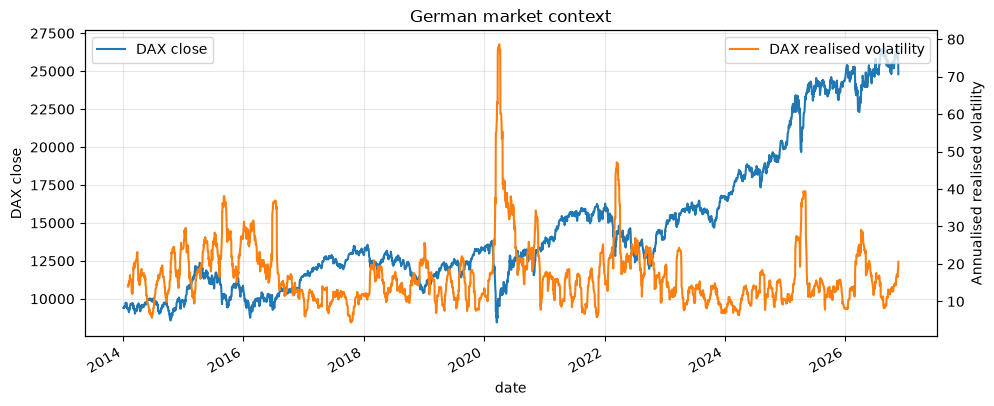

,share_of_days
regime_state,
normal,0.752294
elevated,0.247706


In [4]:
context = table("market_ctx")
if not context.empty:
    context["date"] = pd.to_datetime(context["date"])
    ctx = context.drop_duplicates("date").set_index("date").sort_index()
    fig, ax = plt.subplots()
    right = ax.twinx()
    ctx["spy_close"].plot(ax=ax, color="tab:blue", label="DAX close")
    ctx["vix"].plot(ax=right, color="tab:orange", label="DAX realised volatility")
    ax.set_ylabel("DAX close"); right.set_ylabel("Annualised realised volatility")
    right.grid(False); ax.legend(loc="upper left"); right.legend(loc="upper right")
    ax.set_title("German market context"); plt.show()
    display(ctx["regime_state"].value_counts(normalize=True, dropna=False).rename("share_of_days").to_frame())

## 5 · Events

Count event families by year and events by size bucket.
The hit rate uses only events with a known forward outcome.


In [5]:
events = table("events")
if not events.empty:
    display(pd.crosstab(events["event_family"], pd.to_datetime(events["date"]).dt.year))
    display(events.groupby("cap_bucket", dropna=False).size().rename("events").to_frame())
    known = events.loc[events["growth_future_10d"].notna()].copy()
    if known.empty:
        print("missing: events.growth_future_10d")
    else:
        known["hit"] = known["growth_future_10d"] >= 1.02
        display(known.groupby("event_family").agg(n=("hit", "size"), share_at_least_2pct=("hit", "mean")))

date,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
event_family,,,,,,,,,,,,,
earnings_crash,2,1,3,0,2,9,12,4,7,8,14,14,16
earnings_down,133,138,158,149,154,162,175,184,171,152,150,158,158
earnings_up,141,152,129,159,160,180,174,163,177,159,172,167,147
momentum_breakout,362,494,497,512,396,621,665,667,580,628,555,654,632
shock_crash,15,19,20,11,24,24,80,30,74,39,43,59,58


,events
cap_bucket,
large,4310
mid,5880
small,1783


,n,share_at_least_2pct
event_family,,
earnings_crash,91,0.472527
earnings_down,2028,0.360454
earnings_up,2068,0.374275
momentum_breakout,7252,0.356453
shock_crash,490,0.395918


## 6 · Earnings-date alignment check

Map release timestamps to Xetra sessions using the market's local close.
Use every mapped German release in the study period, including releases without a selected event.
Compare absolute close-to-close returns around the mapped session using `.DE` prices only.
Missing prices stay missing. Largest-move shares use complete windows and split ties equally.

Moving a release to the day with the largest price change would use future prices to set its date.
That would introduce look-ahead. This check diagnoses timing errors and leaves the timestamps unchanged.


In [6]:
consensus_eps = table("consensus_eps")
session_dates = (context["date"] if not context.empty else
                 market.loc[market["ticker"].eq("^GDAXI"), "date"] if not market.empty else [])
sessions = pd.DatetimeIndex(session_dates).normalize().unique().sort_values()
if len(sessions) == 0:
    print("missing: Xetra sessions")
elif not consensus_eps.empty and not prices_de.empty:
    releases = consensus.release_session_dates(consensus_eps, sessions, config.MARKETS["de"])
    releases = releases.loc[releases["ticker"].str.endswith(".DE", na=False)
                            & releases["release_local"].ge(pd.Timestamp("2014-06-01", tz="Europe/Berlin"))].copy()
    if releases.empty:
        print("missing: mapped German releases from 2014-06-01")
    else:
        xetra = prices_de.loc[prices_de["ticker"].str.endswith(".DE", na=False)].copy()
        xetra["date"] = pd.to_datetime(xetra["date"])
        close = xetra.pivot_table(index="date", columns="ticker", values="close").reindex(sessions)
        daily_abs = close.pct_change(fill_method=None).abs()
        values = daily_abs.to_numpy()
        rows = sessions.get_indexer(releases["date"])
        cols = daily_abs.columns.get_indexer(releases["ticker"])
        offsets = list(range(-2, 3))
        windows = releases[["ticker", "date", "release_local"]].copy()
        for offset in offsets:
            positions = rows + offset
            valid = (rows >= 0) & (positions >= 0) & (positions < len(sessions)) & (cols >= 0)
            moves = np.full(len(windows), np.nan)
            moves[valid] = values[positions[valid], cols[valid]]
            windows[offset] = moves
        moves = windows[offsets]
        complete = moves.dropna()
        largest = complete.eq(complete.max(axis=1), axis=0)
        largest_share = largest.div(largest.sum(axis=1), axis=0).mean()
        print("mapped .DE releases from 2014-06-01:", len(windows))
        print("complete windows:", len(complete), "| incomplete windows:", len(windows) - len(complete))
        if complete.empty:
            print("missing: complete earnings return windows")
        display(pd.DataFrame({"median_abs_daily_return": moves.median(), "n_returns": moves.count(),
                              "largest_move_share": largest_share}).rename_axis("session_offset"))
        hour_buckets = ["0–5", "6–8", "9–12", "13–17", "18–23"]
        windows["berlin_release_hour"] = pd.cut(windows["release_local"].dt.hour,
                                                bins=[-1, 5, 8, 12, 17, 23], labels=hour_buckets)
        by_hour = windows.groupby("berlin_release_hour", observed=False)
        print("median absolute daily returns by Berlin release hour:")
        display(by_hour[offsets].median())
        display(by_hour.size().rename("releases").to_frame())

mapped .DE releases from 2014-06-01: 4823
complete windows: 4817 | incomplete windows: 6


,median_abs_daily_return,n_returns,largest_move_share
session_offset,,,
-2,0.010753,4817,0.104422
-1,0.011545,4817,0.145526
0,0.022953,4817,0.418933
1,0.014723,4817,0.195765
2,0.012509,4817,0.135354


median absolute daily returns by Berlin release hour:


,-2,-1,0,1,2
berlin_release_hour,,,,,
0–5,0.011215,0.012541,0.023229,0.016032,0.013443
6–8,0.010033,0.009995,0.023246,0.013841,0.011429
9–12,0.011156,0.011176,0.024286,0.014796,0.013774
13–17,0.011393,0.011099,0.024306,0.015559,0.012834
18–23,0.010405,0.018040,0.016736,0.012826,0.011707


,releases
berlin_release_hour,
0–5,1500
6–8,1429
9–12,817
13–17,647
18–23,430


## 7 · Research results

Read the recorded production model and the model comparison's VALIDATION columns.
TEST results are reported in the strategy table. They do not choose the model.
The walk-forward chart uses saved equity and the DAX buy-and-hold curve when present.


{
 "name": "rf",
 "threshold": 0.5,
 "val_auc": 0.5326000613038728,
 "test_auc": 0.5429435664507283,
 "target": "is_positive_growth_10d (growth_future_10d >= 1.02)",
 "test_base_rate": 0.3796139519133085,
 "test_precision_at_threshold": 0.52,
 "n_features": 171,
 "split_sizes": {
  "train": 6943,
  "test": 2997,
  "validation": 1988,
  "purged": 45
 }
}


,variant,learner,feature_set,n_features,val_auc,val_prec_top10,val_prec_top20,val_within_date_corr,val_when_auc,val_base_rate,val_n
0,a_pooled,rf,pooled,146,0.534187,0.419192,0.448363,0.051346,0.524395,0.375252,1988
1,a_pooled,lgbm,pooled,146,0.510438,0.484848,0.420655,0.034038,0.511459,0.375252,1988
2,a_pooled,logreg,pooled,146,0.501856,0.393939,0.408060,-0.011567,0.502732,0.375252,1988
3,a2_pooled_month_wom,rf,pooled_wom,206,0.542102,0.434343,0.435768,0.039355,0.534315,0.375252,1988
4,a2_pooled_month_wom,lgbm,pooled_wom,206,0.529356,0.464646,0.430730,0.043302,0.527584,0.375252,1988
5,a2_pooled_month_wom,logreg,pooled_wom,206,0.535105,0.439394,0.415617,-0.011984,0.541668,0.375252,1988
6,b1_cs_keep_market,rf,cs_keep_market,210,0.530882,0.464646,0.445844,0.046887,0.521786,0.375252,1988
7,b1_cs_keep_market,lgbm,cs_keep_market,210,0.526007,0.464646,0.443325,0.059614,0.523047,0.375252,1988
8,b1_cs_keep_market,logreg,cs_keep_market,210,0.505744,0.414141,0.400504,0.003921,0.505396,0.375252,1988
9,b2_cs_drop_market,rf,cs_drop_market,171,0.532600,0.484848,0.410579,0.044849,0.526563,0.375252,1988


,name,cagr,sharpe,max_drawdown,n_trades
0,all_events_unconditional,0.136666,0.617841,-0.268358,353.0
1,model_top5,0.022999,0.359709,-0.116944,20.0
2,model_top3_concentrated,0.034000,0.345573,-0.190616,20.0
3,model_top5_risk_managed,0.004901,0.142449,-0.064770,21.0
4,model_pead_only,0.007143,0.179638,-0.092607,13.0
5,model_crash_only,0.042957,0.862263,-0.058388,7.0
6,model_breakout_only,-0.011876,-0.524195,-0.048663,2.0
7,model_long_short,-0.033384,-0.393644,-0.169193,128.0
8,guide_armA_momentum_breakout,-0.003261,-0.011937,-0.109195,488.0
9,guide_armB_plus_consolidation,0.004900,0.348420,-0.021056,15.0


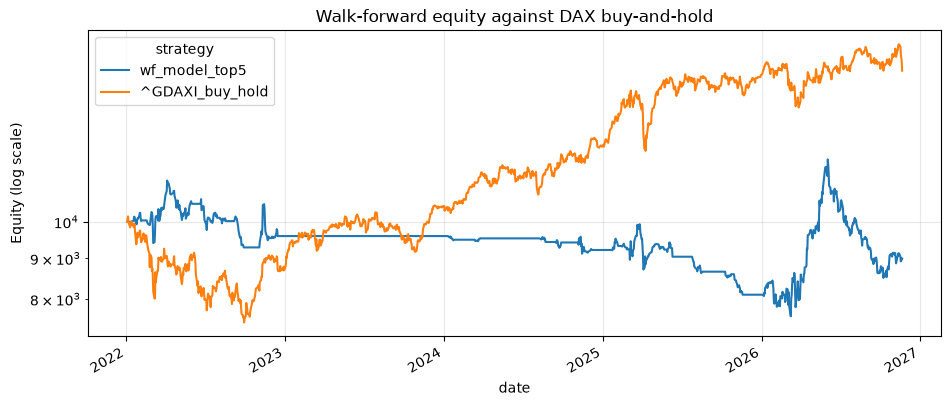

In [7]:
metrics = artifacts.load_metrics()
if not metrics:
    print("missing: metrics.json")
else:
    if metrics.get("model"):
        print(json.dumps(metrics["model"], indent=1, default=str))
    else:
        print("missing: metrics.model")
comparison = frame("model_comparison.parquet")
if not comparison.empty:
    identifiers = [c for c in ["variant", "learner", "feature_set", "n_features"] if c in comparison]
    display(comparison[identifiers + [c for c in comparison if c.startswith("val_")]])
if metrics:
    results = pd.DataFrame(metrics.get("strategies", []) + metrics.get("benchmarks", []))
    if results.empty:
        print("missing: metrics.strategies and metrics.benchmarks")
    else:
        display(results.reindex(columns=["name", "cagr", "sharpe", "max_drawdown", "n_trades"]))
wfe = frame("walkforward_equity.parquet")
if not wfe.empty:
    wfe["date"] = pd.to_datetime(wfe["date"])
    curves = wfe.pivot_table(index="date", columns="strategy", values="equity").sort_index()
    names = ["wf_model_top5", "^GDAXI_buy_hold"]
    for name in names:
        if name not in curves:
            print(f"missing: {name}")
    present = [name for name in names if name in curves]
    if present:
        curves[present].plot(logy=True, title="Walk-forward equity against DAX buy-and-hold")
        plt.ylabel("Equity (log scale)"); plt.show()

## 8 · Pooled US + DE comparison

The comparison is read from the German artifacts directory.
The winner is chosen on German VALIDATION. TEST is reported only.


In [8]:
pooled = frame("pooled_comparison.parquet")
if not pooled.empty:
    display(pooled[["variant", "learner", "n_train_us", "n_train_de", "val_auc", "val_prec_top10", "test_auc", "winner"]])
else:
    print("Create the comparison outside this notebook with:")
    print(f'python -m driftrev.research_pooled --us-warehouse "{config.DATA_ROOT / "warehouse.duckdb"}" '
          f'--de-warehouse "{config.WAREHOUSE}" --out "{config.ARTIFACTS_DIR / "pooled_comparison.parquet"}"')

,variant,learner,n_train_us,n_train_de,val_auc,val_prec_top10,test_auc,winner
0,de_only,lgbm,0,6943,0.511982,0.464646,0.526094,False
1,de_only,rf,0,6943,0.517476,0.419192,0.532940,False
2,pooled_all,lgbm,79544,6943,0.534971,0.409091,0.537045,False
3,pooled_all,rf,79544,6943,0.536729,0.439394,0.534465,True
4,pooled_same_families,lgbm,44861,6943,0.542334,0.414141,0.525703,False
5,pooled_same_families,rf,44861,6943,0.518367,0.383838,0.539117,False
6,us_transfer_same_families,lgbm,44861,0,0.528739,0.459596,0.519964,False
7,us_transfer_same_families,rf,44861,0,0.532686,0.383838,0.513582,False


## 9 · Readings

The recorded German signal is weak. The strategy does not beat DAX buy-and-hold.
Pooling US and German events changes results within noise. No German post-earnings drift is visible.
Adding earnings does not improve the recorded walk-forward result.
See [README §15](../README.md#15-extension-german-equities-on-xetra) and
[OPL R7](../docs/architecture/opm/OPL.md#r7--german-equities-on-deutsche-börse-xetra) for the recorded numbers and limitations.
